![Banner](../images/09_13_banner_rs_capstones.png)


# Wild Fire Burned-area Mapping

Burned area mapping using Sentinel-2 satellite data leverages multi-spectral imagery to detect, assess, and monitor regions affected by wildfires. By combining specific spectral bands, especially in the near-infrared and shortwave infrared range, it is possible to delineate burned areas and estimate burn severity over large landscapes efficiently.


## Overview

Sentinel-2 burn radiometric indices are mathematical combinations of spectral bands from the Sentinel-2 satellite used to detect and measure the effects of fire on vegetation, soil, and land surfaces. They help researchers identify burned areas, estimate burn severity, monitor vegetation damage, and assess post-fire recovery using satellite imagery.


### Important Sentinel-2 spectral bands

Sentinel-2 provides 13 spectral bands. Several are particularly useful for burn detection.

| Band             | Wavelength | Spatial resolution | Relevance to fire                               |
| ---------------- | ---------- | ------------------ | ----------------------------------------------- |
| B2 — Blue        | 490 nm     | 10 m               | Surface and atmospheric information             |
| B3 — Green       | 560 nm     | 10 m               | Vegetation and surface reflectance              |
| B4 — Red         | 665 nm     | 10 m               | Chlorophyll absorption and vegetation damage    |
| B8 — NIR         | 842 nm     | 10 m               | Vegetation structure and canopy damage          |
| B8A — Narrow NIR | 865 nm     | 20 m               | Vegetation and canopy characteristics           |
| B11 — SWIR1      | 1610 nm    | 20 m               | Vegetation moisture and burned surfaces         |
| B12 — SWIR2      | 2190 nm    | 20 m               | Burn scars, dry vegetation, and surface changes |

Key idea: Near-infrared (NIR) reflectance is generally high for healthy vegetation, while shortwave infrared (SWIR) reflectance often increases as vegetation dries or burns. This makes NIR–SWIR combinations particularly valuable for mapping burned areas.

Note that the original spatial resolution of B11 and B12 is 20 m, even when the final index map is resampled to 10 m.


### Major Sentinel-2 burn indices and their formulas

The following are widely used indices for burned-area mapping and fire-impact assessment.&#x20;


#### Normalized Burn Ratio (NBR)

Purpose: Detect burned areas and assess changes in vegetation caused by fire.

$$\mathrm{NBR}=\frac{B8-B12}{B8+B12} $$

- B8: Near-infrared (NIR)
- B12: Shortwave infrared 2 (SWIR2)

Interpretation:

- High positive NBR: often healthy, green vegetation.
- Low NBR: potentially burned vegetation, bare soil, or dry vegetation.
- Negative NBR: surfaces with relatively high SWIR reflectance compared with NIR.

NBR is usually the first index to calculate when mapping wildfire damage.


#### Differenced Normalized Burn Ratio (dNBR)

Purpose: Estimate the magnitude of vegetation change between pre-fire and post-fire images.

$$ \mathrm{dNBR}=\mathrm{NBR}\_{pre}-\mathrm{NBR}\_{post} $$


A commonly used set of approximate dNBR severity classes is shown below. These thresholds are illustrative; classification systems should be adapted to local vegetation and validated with field data.

| dNBR           | Approximate interpretation                     |
| -------------- | ---------------------------------------------- |
| Below −0.25    | Substantial post-fire greening or other change |
| −0.25 to −0.10 | Moderate greening                              |
| −0.10 to +0.10 | Little apparent change                         |
| +0.10 to +0.27 | Low severity                                   |
| +0.27 to +0.44 | Moderate-low severity                          |
| +0.44 to +0.66 | Moderate-high severity                         |
| Above +0.66    | High severity                                  |


#### Normalized Burn Ratio 2 (NBR2)

Purpose: Examine changes in surface and vegetation moisture using two SWIR bands.

$$ \mathrm{NBR2}=\frac{B11-B12}{B11+B12} $$

- B11: SWIR1
- B12: SWIR2

NBR2 can help distinguish burned surfaces from unburned vegetation and assess changes associated with drying. It is also useful for tracking post-fire conditions, although soil type and background moisture can affect its performance.


#### Burned Area Index (BAI)

Purpose: Highlight pixels whose red and NIR reflectance resembles the spectral characteristics of burned surfaces.

$$ \mathrm{BAI}= \frac{1}{(0.1-B4)^2+(0.06-B8)^2} $$

- B4: Red
- B8: NIR

BAI is designed to emphasize pixels near reference reflectance values associated with burned surfaces. Higher values can indicate potential burned areas.

Important: BAI is sensitive to reflectance scaling. The reference values 0.1 and 0.06 assume reflectance is expressed as a fraction (for example, 0.10 rather than 1000 in scaled Sentinel-2 data).


#### Burned Area Index for Sentinel-2 (BAIS2)

Purpose: Use visible, red-edge, NIR, and SWIR bands to improve burned-area detection.

$$ \begin{aligned} \mathrm{BAIS2}={}& \left(1-\sqrt{\frac{B6B7B8A}{B4}}\right)\\\ &\times\left(\frac{B12-B8A}{\sqrt{B12+B8A}}+1\right) \end{aligned} $$

This index incorporates vegetation red-edge bands B6 and B7, narrow NIR B8A, red B4, and SWIR2 B12. It was developed specifically for Sentinel-2 imagery and can provide additional discrimination between burned and unburned surfaces.&#x20;


#### Mid-Infrared Burn Index (MIRBI)

Purpose: Separate burned surfaces from unburned backgrounds using SWIR reflectance.

$$\mathrm{MIRBI}=10B12-9.8B11+2$$

MIRBI uses the contrast between the two SWIR bands. It is especially useful in some dry environments where burned ground, ash, and dry vegetation have distinct SWIR responses.

Use the reflectance scaling and formulation appropriate to the source of your imagery; MIRBI is not a normalized index and its numerical range depends on the input scale.&#x20;


## Comparison of the main burn indices

| Index | Main bands           | Primary application                         |
| ----- | -------------------- | ------------------------------------------- |
| NBR   | B8, B12              | General burned-area detection               |
| dNBR  | Pre/post-fire NBR    | Burn severity assessment                    |
| NBR2  | B11, B12             | Surface moisture and burn-related change    |
| BAI   | B4, B8               | Highlighting potential burned pixels        |
| BAIS2 | B4, B6, B7, B8A, B12 | Sentinel-2 burned-area discrimination       |
| MIRBI | B11, B12             | Burned surfaces versus unburned backgrounds |
| NDVI  | B8, B4               | Vegetation loss and recovery                |
| NDMI  | B8, B11              | Vegetation moisture changes                 |

The NDVI and NDMI are not exclusively burn indices, but they are useful supporting indicators for interpreting fire damage and recovery.


## How to calculate burn indices from Sentinel-2 imagery


Step 1 — Obtain satellite images

Download Sentinel-2 Level-2A surface reflectance imagery from before and after the fire.

Step 2 — Preprocess the images

Mask clouds, cirrus, cloud shadows, and invalid pixels. Ensure both dates use compatible reflectance values, spatial alignment, and projection.

Step 3 — Calculate the indices

Apply the equations to each pixel to create NBR, NBR2, BAI, BAIS2, or MIRBI raster layers.

Step 4 — Map burn extent and severity

Calculate dNBR from the pre- and post-fire NBR layers, classify the change, and validate the result against reference data.

The sections below do this locally with GeoLattice. `get_images` searches the Microsoft Planetary Computer STAC catalog and writes AOI-clipped GeoTIFFs to disk. Scaling, cloud masking, compositing, burn indices, and the GeoTIFF export then run on those files.


## Which index should you choose?

- For burned-area mapping: Start with NBR and compare it with BAI or BAIS2.
- For burn severity: Use dNBR, preferably supported by field observations or an established local classification.
- For dry vegetation and soil backgrounds: Test MIRBI and NBR2 alongside NBR.
- For vegetation recovery: Track NDVI and NBR across multiple post-fire dates.

My recommendation: Start with NBR, dNBR, and BAIS2, then compare their performance using reference burned-area data. No single index performs best in every ecosystem, and drought, harvesting, bare soil, and seasonal vegetation changes can mimic fire-related spectral changes.


# Python Tutorial: Burned Area Mapping with Sentinel-2 for California Wildfires (2026)

This tutorial develops a reproducible geospatial workflow to map wildfire burn scars, estimate fire-related vegetation change, calculate burned area, and visualize results using Python and Sentinel-2 satellite imagery.

We'll use the official CAL FIRE [2026 Incident Archive](https://www.fire.ca.gov/incidents/2026?utm_source=chatgpt.com) to select a real fire, then analyze pre-fire and post-fire satellite imagery. The archive currently lists major 2026 incidents including the Bug Fire, Biscar Fire, Plaskett Fire, and Timber Fire, with reported final or current acreage and containment status.&#x20;


## Select a wildfire for the case study

The CAL FIRE archive currently reports the following large incidents:


Bug Fire: Lassen and Sierra counties · Started August 8, 2026,  93,733 acres, 100% containment listed in the archive.

Biscar Fire: Lassen County · Started July 18, 2026, 69,355 acres, 98% containment listed in the archive.

Plaskett Fire: Monterey County · Started August 26, 2026,  30,124 acres, 100% containment listed in the archive.

These are the incident acreage figures published by CAL FIRE, not independent satellite-derived measurements. Imagery must be examined to estimate the observed burned footprint.&#x20;

For this tutorial, we'll use the Bug Fire as the example because of its large reported footprint. The same workflow can be adapted to the other fires. A large fire may cover multiple Sentinel-2 tiles, so use a fire perimeter to constrain the analysis rather than downloading an entire satellite scene unnecessarily.


## What will we produce?

- Satellite imagery: Sentinel-2 Level-2A surface reflectance before and after the fire

- Burn index rasters: NBR, dNBR, NDVI, and optionally NBR2 and BAIS2

- Burned-area maps

- A spatial map of candidate burned pixels and severity classes- Estimated hectares and acres, change statistics, and accuracy assessment

A key distinction: burned-area extent and burn severity are different products. Burned area answers “where did the fire burn?” Burn severity estimates the magnitude of ecological and surface change within the affected area.


## Set up your Python environment

This tutorial uses GeoLattice for local image download and processing. `geolattice.rsense.get_images` searches a STAC catalog and saves only the bands you ask for, clipped to the fire perimeter. Later cells read those GeoTIFFs, scale them to reflectance, mask clouds with the Scene Classification Layer, and calculate burn indices.

The dataset is Sentinel-2 Level-2A surface reflectance from the Microsoft Planetary Computer. Reflectance bands are stored as integers scaled by 10,000, with a −1000 offset on scenes processed since 25 January 2022. The Scene Classification Layer (SCL) identifies clouds, shadows, water, and vegetation.


### Install the required libraries

`rsense-access` installs the Planetary Computer STAC client that `get_images` uses. Run this once in the notebook environment:


If you're using Ubuntu and an existing Python environment, activate your virtual environment before running the installation.


### Import GeoLattice and required libraries


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json
import warnings
from collections import defaultdict
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from rasterio.enums import Resampling

import geolattice.rsense as rs
from geolattice.network import is_online
from geolattice.rsense.get_images import get_images, search_images
from geolattice.rsense.optical.sensors import sentinel2_burn_indices

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110})

ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
print(
    "geolattice.rsense", rs.__version__,
    "| backend:", rs.set_backend("cpu"),
    "| Planetary Computer reachable:", ONLINE,
)

# Downloaded scenes and the GeoTIFFs this notebook writes.
DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones/bug_fire_sentinel2")
DATA.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("outputs/bug_fire")
OUT_DIR.mkdir(parents=True, exist_ok=True)


geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


GeoLattice is ready to download Sentinel-2 scenes into `Data/08_remote_sensing/08_11_Capstones/bug_fire_sentinel2` and process them on this machine. Files that are already in that folder are skipped on the next run.


## Obtain the fire perimeter

A fire perimeter is a polygon outlining the reported extent of a fire. It gives us an area of interest (AOI) so we can restrict satellite processing to the relevant region.

The next cell reads `Data/08_remote_sensing/08_11_Capstones/bug_fire_sentinel2/bug_fire_perimeter.geojson` when that file is already present. Otherwise it downloads the Bug Fire polygon from the [NIFC WFIGS Interagency Fire Perimeters](https://data-nifc.opendata.arcgis.com/datasets/nifc::wfigs-interagency-fire-perimeters) service: incident name `Bug`, state `US-CA`. That record is the Lassen County fire discovered on 8 August 2026, about 93,733 acres. The current-perimeter layer drops incidents after they leave the active list, so the query uses the full interagency archive.

Use this fire footprint as the AOI. A county boundary would download far more imagery than the burn.


### Read and inspect the perimeter


In [ ]:
import json
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import geopandas as gpd
import pandas as pd


# This section downloads or loads the fire perimeter for the Bug Fire, checks/cleans the GeoDataFrame, and provides summary info.
# 1. Check for perimeter GeoJSON. If missing, it queries the NIFC ArcGIS service for the Bug Fire perimeter in California, saves as GeoJSON.
# 2. Reads the GeoJSON with geopandas, fixes CRS, and if needed, selects only features from the correct year and largest area.
# 3. Keeps only relevant columns, prints out summary info about the loaded fire perimeter, and displays it as an interactive map.

if "DATA" not in globals():
    DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones/bug_fire_sentinel2")
perimeter_path = DATA / "bug_fire_perimeter.geojson"
perimeter_path.parent.mkdir(parents=True, exist_ok=True)

# URL for the full archive of fire perimeters (not just active fires)
WFIGS_PERIMETERS = (
    "https://services3.arcgis.com/T4QMspbfLg3qTGWY/arcgis/rest/services/"
    "WFIGS_Interagency_Perimeters/FeatureServer/0/query"
)

# Only download the perimeter if we don't already have it locally
if not perimeter_path.exists():
    # Construct request parameters to select the Bug Fire in CA and get wanted fields as GeoJSON with specified SRID and geometry precision
    query = urlencode({
        "where": "poly_IncidentName='Bug' AND attr_POOState='US-CA'",
        "outFields": ",".join([
            "poly_IncidentName",
            "poly_GISAcres",
            "attr_POOState",
            "attr_POOCounty",
            "attr_FireDiscoveryDateTime",
        ]),
        "f": "geojson",
        "outSR": "4326",
        "geometryPrecision": "5",
    })
    request = Request(
        WFIGS_PERIMETERS + "?" + query,
        headers={"User-Agent": "geolattice-tutorial/1.0"},
    )
    # Fetch the result (timeout set generously), load as JSON
    with urlopen(request, timeout=120) as response:
        payload = response.read()
    downloaded = json.loads(payload)
    # If no features were returned, halt with an informative error
    if not downloaded.get("features"):
        raise RuntimeError(
            "NIFC returned no Bug Fire perimeter for California. "
            f"Save a perimeter GeoJSON at {perimeter_path}."
        )
    # Save the downloaded result
    perimeter_path.write_bytes(payload)
    print("Downloaded Bug Fire perimeter to", perimeter_path.resolve())
else:
    print("Using existing perimeter", perimeter_path.resolve())

# Load the perimeter as a GeoDataFrame
fire_gdf = gpd.read_file(perimeter_path)
if fire_gdf.empty:
    raise ValueError("The perimeter file contains no features.")

# Ensure the GeoDataFrame has a CRS; if not, set it to WGS84
if fire_gdf.crs is None:
    fire_gdf = fire_gdf.set_crs("EPSG:4326")
fire_gdf = fire_gdf.to_crs("EPSG:4326")

# If the fire discovery time is present, parse it and filter for fires in 2026 only
if "attr_FireDiscoveryDateTime" in fire_gdf.columns:
    fire_gdf["discovery"] = pd.to_datetime(
        fire_gdf["attr_FireDiscoveryDateTime"], unit="ms", utc=True
    )
    in_2026 = fire_gdf["discovery"].dt.year == 2026
    if in_2026.any():
        fire_gdf = fire_gdf.loc[in_2026].copy()

# If for some reason multiple features remain, keep only the largest by reported acres
if "poly_GISAcres" in fire_gdf.columns and len(fire_gdf) > 1:
    fire_gdf = fire_gdf.sort_values("poly_GISAcres", ascending=False).head(1)

# Choose a subset of columns to keep for clarity
keep = [
    column for column in (
        "poly_IncidentName", "poly_GISAcres", "attr_POOCounty", "discovery", "geometry"
    )
    if column in fire_gdf.columns
]
fire_gdf = fire_gdf[keep].reset_index(drop=True)

# Print basic info about the fire perimeter for inspection and debugging
print(fire_gdf.drop(columns="geometry"))
print("CRS:", fire_gdf.crs)
print("Number of features:", len(fire_gdf))
print(
    "Bounds (west, south, east, north):",
    tuple(round(float(v), 4) for v in fire_gdf.total_bounds),
)

# Display perimeter as an interactive map (folium/leaflet in a Jupyter notebook)
fire_gdf.explore()

Using existing perimeter /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/data/bug_fire_sentinel2/bug_fire_perimeter.geojson
  poly_IncidentName  poly_GISAcres attr_POOCounty                 discovery
0               Bug       93733.34         Lassen 2026-08-08 22:30:49+00:00
CRS: EPSG:4326
Number of features: 1
Bounds (west, south, east, north): (-120.0422, 39.6901, -119.7086, 39.9692)


The interactive map allows you to inspect the polygon. If the map shows the entire county rather than the fire footprint, stop and obtain the correct perimeter.


### Simplify the perimeter for processing


In [ ]:
from shapely import make_valid
from shapely.ops import unary_union

# Function to repair and filter geometry for valid polygons only.
# Fire perimeters from NIFC data sometimes have self-intersections or invalid shapes.
# - make_valid() attempts to fix these issues.
# - If the result is a GeometryCollection (e.g., a self-intersecting ring becoming lines and polygons),
#   we extract only the Polygon or MultiPolygon parts with nonzero area, and union them together.
def polygon_parts(geom):
    geom = make_valid(geom)
    if geom.geom_type == "GeometryCollection":
        parts = [
            part for part in geom.geoms
            if part.geom_type in ("Polygon", "MultiPolygon") and part.area > 0
        ]
        geom = unary_union(parts)
    return geom

# Copy the fire perimeter GeoDataFrame so we don't alter the original
fire_gdf = fire_gdf.copy()

# Apply the polygon_parts function to each geometry in the GeoDataFrame, so all invalid or complex shapes are fixed,
# and only the actual burnt area polygons are kept.
fire_gdf.geometry = [polygon_parts(geom) for geom in fire_gdf.geometry]

# Combine all fire perimeter polygons into one geometry, in case there are overlapping or fragmented parts.
fire_shape = fire_gdf.geometry.union_all()

# The fire boundary at this stage may be highly detailed (thousands of vertices),
# which can greatly slow down further raster or spatial operations.
# We simplify the boundary using a small tolerance (in degrees: 0.0001 is about 10 meters at the equator)
# and preserve the topology to avoid crossing edges.
simplified = fire_shape.simplify(tolerance=0.0001, preserve_topology=True)

# Run polygon_parts again, in case the simplification step introduces small invalidities or lines.
fire_shape = polygon_parts(simplified)

# Put the simplified perimeter into a new GeoDataFrame to use in later steps,
# setting the correct coordinate reference system (WGS84 / EPSG:4326)
fire_gdf_simple = gpd.GeoDataFrame(geometry=[fire_shape], crs="EPSG:4326")

print("Fire perimeter geometry simplified.")
print("Bounds (west, south, east, north):", tuple(fire_gdf_simple.total_bounds.round(4)))


Fire perimeter geometry simplified.
Bounds (west, south, east, north): (np.float64(-120.0422), np.float64(39.6901), np.float64(-119.7086), np.float64(39.9692))


The simplified geometry is used to limit STAC queries and processing. For final area calculations, retain the original perimeter and use a suitable projected coordinate system.


## Select pre-fire and post-fire dates

The Bug Fire is listed as starting on August 8, 2026.

We can begin with these example windows:

| Period    | Start date      | End date            | Purpose                                           |
| --------- | --------------- | ------------------- | ------------------------------------------------- |
| Pre-fire  | July 15, 2026   | August 8, 2026      | Estimate conditions before ignition               |
| Post-fire | August 20, 2026 | September 20, 2026  | Estimate conditions after the initial fire period |

These dates are initial analysis windows, not verified cloud-free acquisition dates. `search_images` treats both ends as calendar dates. Review the scenes that come back and widen a window if the fire was still spreading, smoke covered the post-fire dates, or the vegetation was already dry before ignition.


In [4]:
PRE_START = "2026-07-15"
PRE_END   = "2026-08-08"

POST_START = "2026-08-20"
POST_END   = "2026-09-20"

print("Pre-fire window:", PRE_START, "to", PRE_END)
print("Post-fire window:", POST_START, "to", POST_END)

Pre-fire window: 2026-07-15 to 2026-08-08
Post-fire window: 2026-08-20 to 2026-09-20


For an actively burning incident, do not assume a post-fire image represents the final burn extent. Select dates after the fire perimeter has stabilized, or use multiple post-fire dates to track progression.


## Download Sentinel-2 imagery with GeoLattice

`search_images` lists Sentinel-2 Level-2A scenes from Planetary Computer. `get_images` then writes each requested band as a GeoTIFF clipped to the fire perimeter. A large fire can cross more than one MGRS tile, so each date may produce more than one scene folder. Those tiles are mosaicked in the next section.

Sentinel-2 imagery can be affected by clouds, cirrus, cloud shadows, smoke, and snow. These may create false burn signals. The SCL band is downloaded with the reflectance bands and is applied after the files are read.


### Download pre-fire imagery


In [ ]:
# Define the list of Sentinel-2 bands we want to download, using the canonical GeoLattice band names.
# - "nir" corresponds to B8, "swir16" to B11, and "swir22" to B12.
# - "rededge2", "rededge3", and "nir08" correspond to B6, B7, and B8A, and are useful for specific indices like BAIS2.
S2_BANDS = [
    "blue", "green", "red", "nir",
    "rededge2", "rededge3", "nir08",
    "swir16", "swir22", "scl",
]

def check_downloaded(out):
    """
    Check if Sentinel-2 images for a particular period have already been downloaded.

    The function checks if at least one 'red.tif' file exists in any subfolder,
    which is used as a proxy for download completion.
    """
    return len(list(out.glob("*/red.tif"))) > 0

def read_downloaded(out):
    """
    Placeholder function that announces existing images are found in 'out'.

    If you need to add logic to read or inspect downloaded data, implement here.
    """
    print(f"Images already downloaded in {out}. Proceeding to read them...")
    # Update this function if post-processing is needed for pre-downloaded images.
    return out

def download_or_read_window(label, start, end):
    """
    For a given label ("pre" or "post") and a date range, check if images are present.
    If so, use those; if not, download new Sentinel-2 images using search_images and get_images.

    Args:
        label (str): a tag for naming ("pre" or "post")
        start (str): start date of the interval (YYYY-MM-DD)
        end   (str): end date of the interval (YYYY-MM-DD)

    Returns:
        Path to the local directory containing imagery for this period.
    """
    out = DATA / label
    # First, check if any imagery is already downloaded for this label.
    if check_downloaded(out):
        return read_downloaded(out)
    # If running offline and no images available, raise error.
    if not ONLINE:
        raise RuntimeError(
            f"Planetary Computer is unreachable and {out} has no downloaded scenes."
        )

    # Query Planetary Computer / Sentinel-2 for scenes over the AOI, in the given date range,
    # filtering for up to 70% cloud cover. Return at most 80 scenes for efficiency.
    found = search_images(
        aoi=fire_gdf_simple,
        dates=(start, end),
        source="planetary",
        collection="sentinel-2-l2a",
        cloud=70,
        limit=80,
        quiet=True,
    )
    # Only keep the most recent scene for each (date, MGRS tile) combination.
    latest = {}
    for item in found.items:
        key = (item.datetime.date().isoformat(), item.properties.get("s2:mgrs_tile"))
        if key not in latest or item.id > latest[key].id:
            latest[key] = item
    # Build the list of scene IDs to download.
    ids = [item.id for item in latest.values()]
    print(f"{label}: {len(found.scenes)} scene(s) listed, downloading {len(ids)} date/tile pair(s)")
    if not ids:
        raise RuntimeError(
            f"No Sentinel-2 scenes for {label} ({start} to {end}). "
            "Check the perimeter and widen the dates."
        )
    # Download the selected scenes, only the requested bands, and clip to the AOI.
    saved = get_images(
        out,
        search=found,
        ids=ids,
        bands=S2_BANDS,
        mode="clip",
        quiet=True,
    )
    print(saved)
    return out

# Download pre-fire imagery (or use existing if present)
pre_dir = download_or_read_window("pre", PRE_START, PRE_END)


Images already downloaded in data/bug_fire_sentinel2/pre. Proceeding to read them...


Each scene is written to its own folder as one GeoTIFF per band (`red.tif`, `nir.tif`, `swir22.tif`, `scl.tif`, and the others in `S2_BANDS`), plus `item.json` with the STAC metadata. `get_images` skips a band file that is already on disk.


### Download post-fire imagery


In [7]:
if (Path("post").exists() and any(Path("post").rglob("red.tif"))):
    print("Post-fire images already downloaded. Reading from disk.")
    post_dir = Path("post")
else:
    post_dir = download_or_read_window("post", POST_START, POST_END)


Images already downloaded in data/bug_fire_sentinel2/post. Proceeding to read them...


Important: If either dataset is empty (0 images), do not continue with the burn calculations. Adjust the dates, check the perimeter, and inspect the image availability.


### Read the GeoTIFFs into a local cube

Scenes from the same date are mosaicked. The Bug Fire crosses the boundary between UTM zones 10 and 11, so every tile is warped into one 20 m grid that covers the whole perimeter. The 10 m bands are resampled onto the 20 m SWIR pixels before that warp, because NBR mixes B8 and B12. SCL uses nearest neighbour because it is a class map. The grid comes from the perimeter, not from the first scene: the first post-fire date only clips the southern tiles, and aligning later dates to that strip would hide most of the burn.


In [ ]:

# Define lists for the bands we want to work with (from Sentinel-2):
BANDS_10M = ["blue", "green", "red", "nir"]     # Bands available at 10 m resolution
BANDS_20M = ["rededge2", "rededge3", "nir08", "swir16", "swir22"]  # 20 m resolution bands
ALL_BANDS = BANDS_10M + BANDS_20M  # All spectral bands we will stack together

def _read_on(scene_dir, name, template, categorical=False):
    """
    Reads a single band GeoTIFF from a scene directory, optionally warping to match a template grid.
    - scene_dir: folder for this tile/scene, e.g. .../pre/2021-07-01/...
    - name: band name (e.g. 'red', 'swir22', 'scl')
    - template: if provided, warp to match this grid (resolution, alignment)
    - categorical: use 'nearest' resampling for masks/classes; 'bilinear' for continuous bands
    """
    path = scene_dir / f"{name}.tif"
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Re-run the download for this window.")
    arr = rs.read(path, masked=False).squeeze("band", drop=True)
    if template is None:
        return arr
    # Use appropriate resampling for categorical (masks) or continuous data
    resampling = Resampling.nearest if categorical else Resampling.bilinear
    return arr.rio.reproject_match(template, resampling=resampling)

def perimeter_grid(aoi_gdf, resolution=20):
    """
    Creates a single analysis grid (raster) that fully covers the AOI (area of interest/perimeter), 
    projected to the UTM zone of the AOI centroid, at the specified resolution (meters).
    Returns (grid_dataarray, projected AOI gdf)
    """
    from rasterio.transform import from_origin

    centroid = aoi_gdf.geometry.iloc[0].centroid
    # Calculate UTM zone and EPSG code based on centroid longitude/latitude
    zone = int((centroid.x + 180) // 6) + 1
    epsg = (32600 if centroid.y >= 0 else 32700) + zone
    aoi_proj = aoi_gdf.to_crs(epsg)
    minx, miny, maxx, maxy = (float(v) for v in aoi_proj.total_bounds)
    # Snap bounds outward to a whole number of resolution-sized pixels
    minx = np.floor(minx / resolution) * resolution
    miny = np.floor(miny / resolution) * resolution
    maxx = np.ceil(maxx / resolution) * resolution
    maxy = np.ceil(maxy / resolution) * resolution
    width = int(round((maxx - minx) / resolution))
    height = int(round((maxy - miny) / resolution))
    transform = from_origin(minx, maxy, resolution, resolution)
    # Create a blank grid covering this extent
    grid = xr.DataArray(
        np.full((height, width), np.nan, dtype="float32"),
        dims=("y", "x"),
        coords={
            "x": minx + (np.arange(width) + 0.5) * resolution,
            "y": maxy - (np.arange(height) + 0.5) * resolution,
        },
        name="grid",
    )
    # Attach the CRS and geotransform to the DataArray for spatial ops
    grid = grid.rio.write_crs(epsg).rio.write_transform(transform)
    return grid, aoi_proj

def _to_analysis_crs(arr, grid, categorical=False):
    """
    Warps a raster tile to match the analysis grid's CRS (projection) and resolution if needed.
    - categorical: use nearest neighbor for class masks (e.g. SCL), otherwise bilinear.
    """
    resampling = Resampling.nearest if categorical else Resampling.bilinear
    if arr.rio.crs == grid.rio.crs:
        return arr
    return arr.rio.reproject(grid.rio.crs, resolution=20, resampling=resampling)

def stack_window(scene_root):
    """
    For all Sentinel-2 tiles (scenes) in a given window (pre- or post-fire):
    - Groups available tiles by date (using the item.json metadata)
    - For each date:
        - Reads all tiles covering the AOI for that date
        - Warps/resamples all bands to the perimeter-wide grid in AOI UTM
        - Mosaics all tiles from the date
        - Clips to AOI polygon
        - Stacks result as a time x band image cube
    Returns an xr.Dataset: dim "time" x all bands (and SCL mask).
    """
    by_date = defaultdict(list)
    # Organize all scenes by date
    for scene_dir in sorted(p for p in Path(scene_root).iterdir() if p.is_dir()):
        meta = scene_dir / "item.json"
        if not meta.exists():
            continue
        item = json.loads(meta.read_text())
        by_date[item["properties"]["datetime"][:10]].append(scene_dir)
    if not by_date:
        raise FileNotFoundError(f"No scene folders with item.json under {scene_root}")

    # Make one grid covering AOI in its UTM zone, at 20 m (even for 10 m bands)
    grid, aoi_proj = perimeter_grid(fire_gdf_simple, resolution=20)
    layers = {name: [] for name in [*ALL_BANDS, "scl"]}
    times = []
    for day in sorted(by_date):
        # Prepare to collect warped tiles for each band/SCL for this day
        tiles = {name: [] for name in layers}
        for scene_dir in by_date[day]:
            # Use swir22 as a reference band for warping 10/20 m rasters
            ref20 = _read_on(scene_dir, "swir22", None)
            # For each 20 m band, read and warp to reference
            for name in BANDS_20M:
                arr = _read_on(scene_dir, name, ref20)
                tiles[name].append(_to_analysis_crs(arr, grid))
            # Repeat for each 10 m band (downsampled to 20 m grid)
            for name in BANDS_10M:
                arr = _read_on(scene_dir, name, ref20)
                tiles[name].append(_to_analysis_crs(arr, grid))
            # Read SCL mask (clouds/shadows etc), using nearest neighbor resampling, preserve class codes
            scl = _read_on(scene_dir, "scl", ref20, categorical=True)
            tiles["scl"].append(_to_analysis_crs(scl, grid, categorical=True))
        # Mosaic overlapping tiles, clip mosaic to AOI, warp to final grid
        for name in layers:
            mosaic = rs.mosaic(tiles[name], crs=grid.rio.crs, resolution=20)
            clipped = rs.clip(mosaic, aoi_proj)
            layers[name].append(
                clipped.rio.reproject_match(
                    grid,
                    resampling=Resampling.nearest if name == "scl" else Resampling.bilinear,
                )
            )
        # Record the date
        times.append(pd.Timestamp(day))
    # Build an xarray Dataset: (time, x, y, band)
    ds = xr.Dataset(
        {name: xr.concat(layers[name], dim="time") for name in ALL_BANDS},
        coords={"time": times},
    )
    ds["scl"] = xr.concat(layers["scl"], dim="time")
    ds = ds.rio.write_crs(grid.rio.crs)
    ds.attrs["pyrsense:sensor"] = "sentinel2"
    return ds

# Build the time-series cubes for pre- and post-fire windows
pre_ds = stack_window(pre_dir)
post_ds = stack_window(post_dir)
print(f"Pre-fire cube:  {len(pre_ds.time)} date(s), shape {dict(pre_ds.sizes)}")
print(f"Post-fire cube: {len(post_ds.time)} date(s), shape {dict(post_ds.sizes)}, CRS {post_ds.rio.crs}")


Pre-fire cube:  11 date(s), shape {'x': 1427, 'y': 1529, 'time': 11}
Post-fire cube: 13 date(s), shape {'x': 1427, 'y': 1529, 'time': 13}, CRS EPSG:32611


## Create pre-fire and post-fire image composites

An image composite combines multiple observations into a single representative image. The median composite reduces the influence of residual clouds and anomalous observations, although it cannot eliminate all artifacts.


In [ ]:
# Step 1: Convert the raw digital numbers in each dataset to surface reflectance values using sensor-specific scaling.
#         The scene classification layer (SCL) is left unchanged as it contains categorical values.
pre_scaled = rs.optical.scale(pre_ds, sensor="sentinel2")
post_scaled = rs.optical.scale(post_ds, sensor="sentinel2")

# Step 2: Mask out pixels identified as clouds, cloud shadows, cirrus, or no-data according to the SCL mask.
#         'mask_clouds' sets these pixels to NaN. We drop the 'scl' variable as it's not needed in composites.
pre_masked = rs.optical.mask_clouds(pre_scaled, sensor="sentinel2").drop_vars("scl")
post_masked = rs.optical.mask_clouds(post_scaled, sensor="sentinel2").drop_vars("scl")

# Step 3: Build a single "composite" image for each time period by calculating the median reflectance value at each pixel location across all dates.
pre_composite = rs.optical.composite(pre_masked, method="median")
post_composite = rs.optical.composite(post_masked, method="median")

# Step 4: The median operation may cause the CRS (spatial reference information) to be dropped, so we restore it.
#         Next, we reproject the post-fire composite so its grid matches the pre-fire composite, enabling direct comparison.
pre_composite = pre_composite.rio.write_crs(pre_ds.rio.crs)
post_composite = post_composite.rio.write_crs(post_ds.rio.crs)
post_composite = post_composite.rio.reproject_match(pre_composite)

# Display information about the generated composites.
print("Pre-fire and post-fire median composites created.")
print("Pre-fire variables:", list(pre_composite.data_vars))
print("Grid:", dict(pre_composite.sizes))


Pre-fire and post-fire median composites created.
Pre-fire variables: ['blue', 'green', 'red', 'nir', 'rededge2', 'rededge3', 'nir08', 'swir16', 'swir22']
Grid: {'x': 1427, 'y': 1529}


Before calculating indices, inspect the true-color imagery.


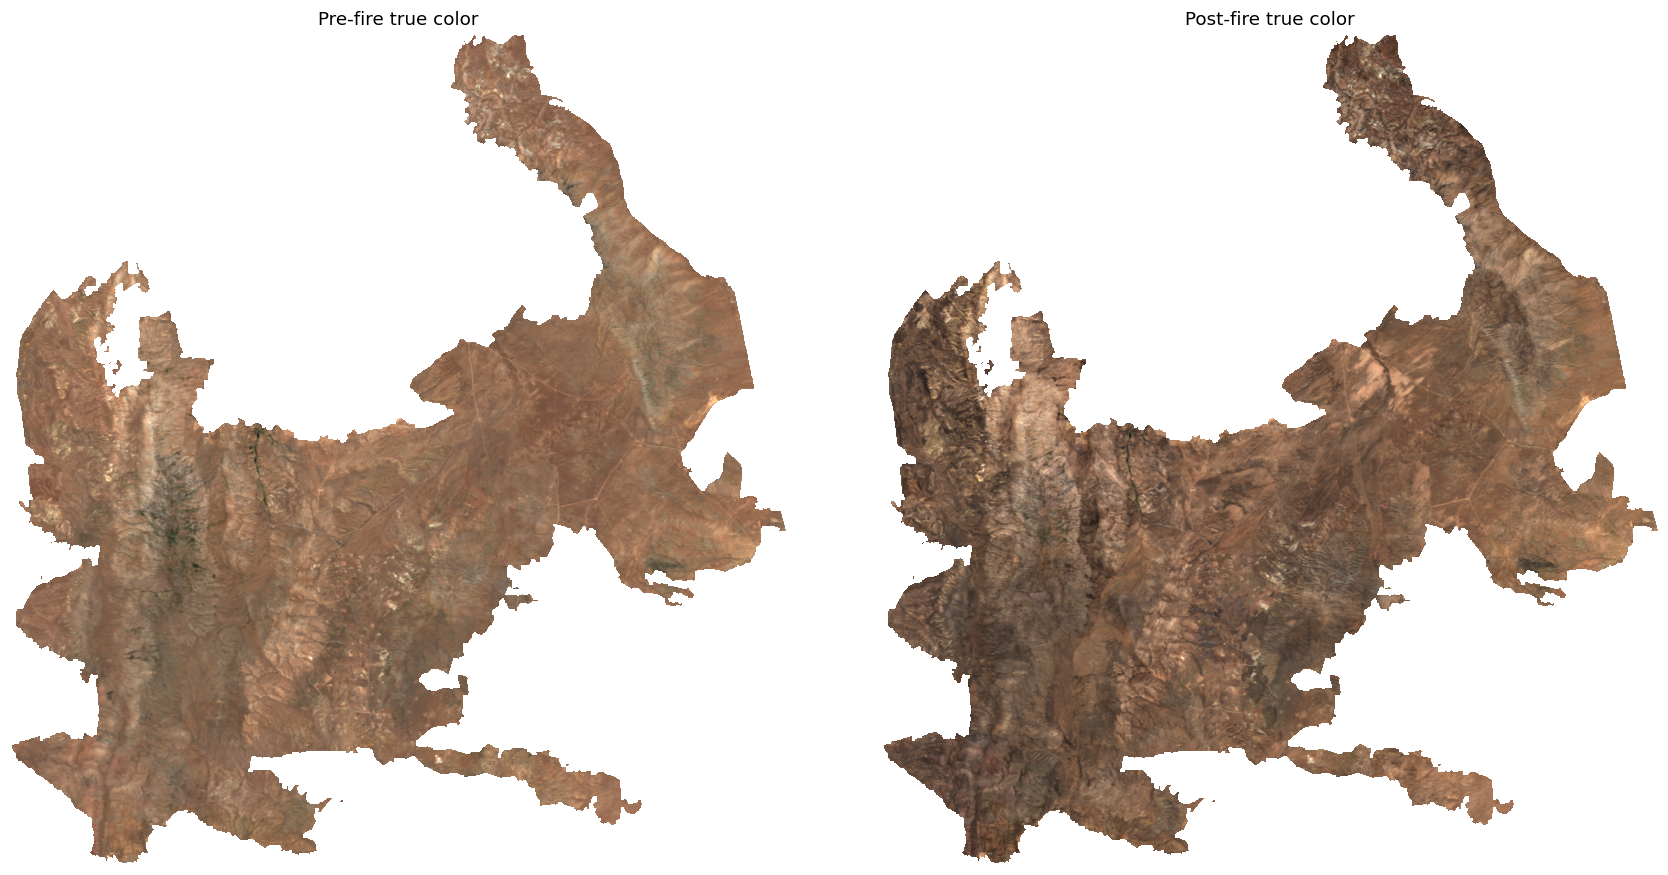

In [10]:
def true_color(composite):
    rgb = np.stack(
        [composite[name].values for name in ("red", "green", "blue")],
        axis=-1,
    )
    return np.clip(rgb * 3.5, 0, 1)


fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(true_color(pre_composite))
axes[0].set_title("Pre-fire true color")
axes[0].axis("off")
axes[1].imshow(true_color(post_composite))
axes[1].set_title("Post-fire true color")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## Calculate Sentinel-2 burn indices using GeoLattice

We will calculate five indices. NBR, dNBR, NBR2, and BAIS2 come from `sentinel2_burn_indices`. NDVI comes from `rs.optical.index`:

1. NBR — Normalized Burn Ratio
2. dNBR — Differenced Normalized Burn Ratio
3. NDVI — Normalized Difference Vegetation Index
4. NBR2 — Normalized Burn Ratio 2
5. BAIS2 — Burned Area Index for Sentinel-2

### Normalized Burn Ratio (NBR)

$$ NBR=\frac{B8-B12}{B8+B12}$$

NBR compares vegetation-sensitive NIR reflectance with SWIR2 reflectance. Fire damage often decreases NBR because vegetation structure and moisture change.


In [11]:
# nir is B8 (842 nm). swir22 is B12 (2190 nm).
nbr_pre = sentinel2_burn_indices.nbr(pre_composite["nir"], pre_composite["swir22"])
nbr_post = sentinel2_burn_indices.nbr(post_composite["nir"], post_composite["swir22"])
print("NBR calculated for the pre-fire and post-fire composites")


NBR calculated for the pre-fire and post-fire composites


### Differenced Normalized Burn Ratio (dNBR)

$$ dNBR=NBR\_{pre}-NBR\_{post} $$


In [12]:
# Calculate dNBR using GeoLattice burn indices module
dnbr = sentinel2_burn_indices.dnbr(nbr_pre, nbr_post)
dnbr = dnbr.rio.write_crs(pre_composite.rio.crs)

# Conventional scaled representation
dnbr_scaled = dnbr * 1000

print("dNBR calculated")

dNBR calculated


Positive dNBR generally indicates a decrease in NBR after the fire. Larger positive values often correspond to stronger vegetation and surface change.

Negative values may indicate greening, but they can also arise from changes in soil moisture, vegetation phenology, or differences between the dates.


### Normalized Difference Vegetation Index (NDVI)

$$ NDVI=\frac{B8-B4}{B8+B4} $$

NDVI measures vegetation greenness. It can help distinguish vegetation loss from other surface changes.


In [13]:
# Same formula as (nir - red) / (nir + red). GeoLattice names the result NDVI.
ndvi_pre = rs.optical.index(pre_composite, "NDVI", sensor="sentinel2")
ndvi_post = rs.optical.index(post_composite, "NDVI", sensor="sentinel2")
delta_ndvi = ndvi_pre - ndvi_post
print("NDVI calculated for the pre-fire and post-fire composites")


NDVI calculated for the pre-fire and post-fire composites


A positive `NDVI_change` means NDVI decreased between the pre-fire and post-fire composites. That is consistent with vegetation loss but does not prove that fire caused the change.


### Normalized Burn Ratio 2 (NBR2)

$$ NBR2=\frac{B11-B12}{B11+B12} $$


In [14]:
# swir16 is B11. swir22 is B12. Both are native 20 m bands.
nbr2_pre = sentinel2_burn_indices.nbr2(pre_composite["swir16"], pre_composite["swir22"])
nbr2_post = sentinel2_burn_indices.nbr2(post_composite["swir16"], post_composite["swir22"])
delta_nbr2 = nbr2_pre - nbr2_post
print("NBR2 calculated for the pre-fire and post-fire composites")


NBR2 calculated for the pre-fire and post-fire composites


NBR2 can help characterize SWIR changes associated with drying and burning. Because both SWIR bands are natively 20 m, it is particularly appropriate for a 20 m analysis.


### Burned Area Index for Sentinel-2 (BAIS2)

BAIS2 uses red (B4), the two red-edge bands (B6, B7), narrow NIR (B8A), and SWIR2 (B12). It was built for Sentinel-2 and is a useful check on NBR. Higher BAIS2 points toward burned surfaces, so compare the post-fire layer with the pre-fire layer directly. Keep BAIS2 on its own scale; the dNBR class breaks belong only to dNBR.


In [15]:
bais2_pre = sentinel2_burn_indices.bais2(
    pre_composite["red"],
    pre_composite["rededge2"],
    pre_composite["rededge3"],
    pre_composite["nir08"],
    pre_composite["swir22"],
)
bais2_post = sentinel2_burn_indices.bais2(
    post_composite["red"],
    post_composite["rededge2"],
    post_composite["rededge3"],
    post_composite["nir08"],
    post_composite["swir22"],
)
print("BAIS2 calculated for the pre-fire and post-fire composites")


BAIS2 calculated for the pre-fire and post-fire composites


## Visualize the burn indices

Create separate visualizations so that you can inspect each index independently.


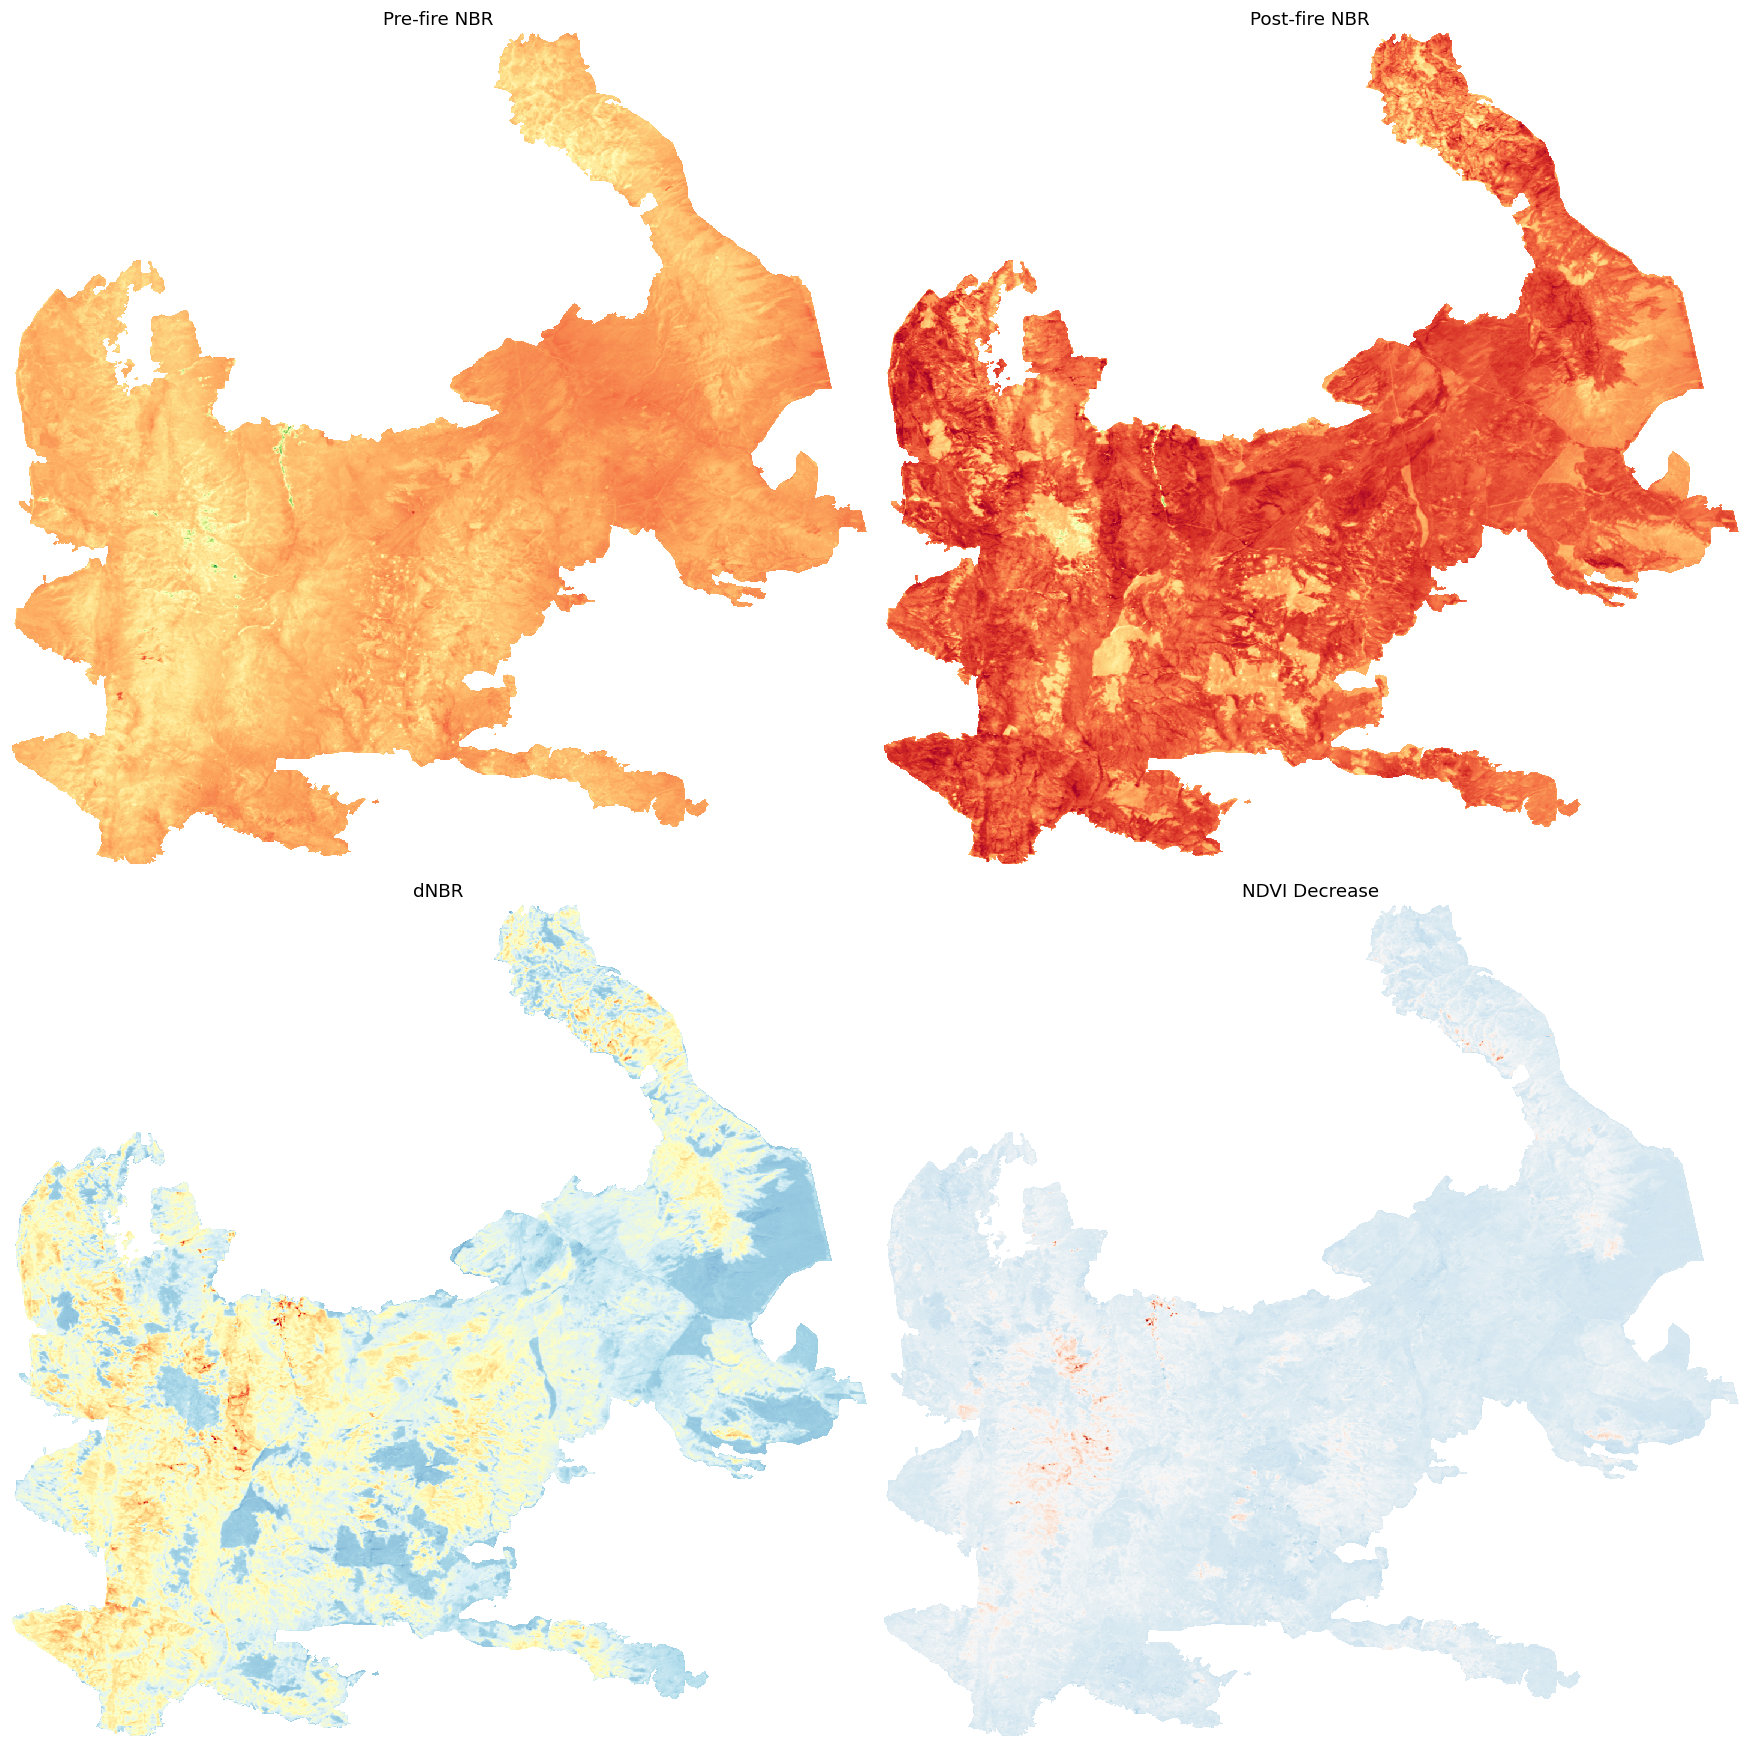

In [16]:
# Visualize burn indices
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Pre-fire NBR
nbr_pre.plot.imshow(ax=axes[0, 0], cmap="RdYlGn", vmin=-0.5, vmax=0.8, add_colorbar=False)
axes[0, 0].set_title("Pre-fire NBR")
axes[0, 0].axis('off')

# Post-fire NBR
nbr_post.plot.imshow(ax=axes[0, 1], cmap="RdYlGn", vmin=-0.5, vmax=0.8, add_colorbar=False)
axes[0, 1].set_title("Post-fire NBR")
axes[0, 1].axis('off')

# dNBR
dnbr.plot.imshow(ax=axes[1, 0], cmap="RdYlBu_r", vmin=-0.3, vmax=0.8, add_colorbar=False)
axes[1, 0].set_title("dNBR")
axes[1, 0].axis('off')

# NDVI change
delta_ndvi.plot.imshow(ax=axes[1, 1], cmap="RdBu_r", vmin=-0.4, vmax=0.6, add_colorbar=False)
axes[1, 1].set_title("NDVI Decrease")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

Interpretation of the dNBR layer:

- Blue: negative change, potentially post-fire greening or another surface change.
- White: relatively little change.
- Yellow and orange: increasing positive change.
- Dark red: large positive change, potentially indicating severe vegetation damage.

These colors are for visualization, not a validated severity classification.


## Classify burned areas and burn severity

A common first-pass approach is to identify candidate burned pixels with positive dNBR above a selected threshold. However, the correct threshold depends on the vegetation type, season, fire characteristics, and local background conditions.

For this exercise, we'll use `dNBR > 0.10` as an illustrative screening threshold, not a validated California-wide burned-area threshold.

### Create a burned-area mask


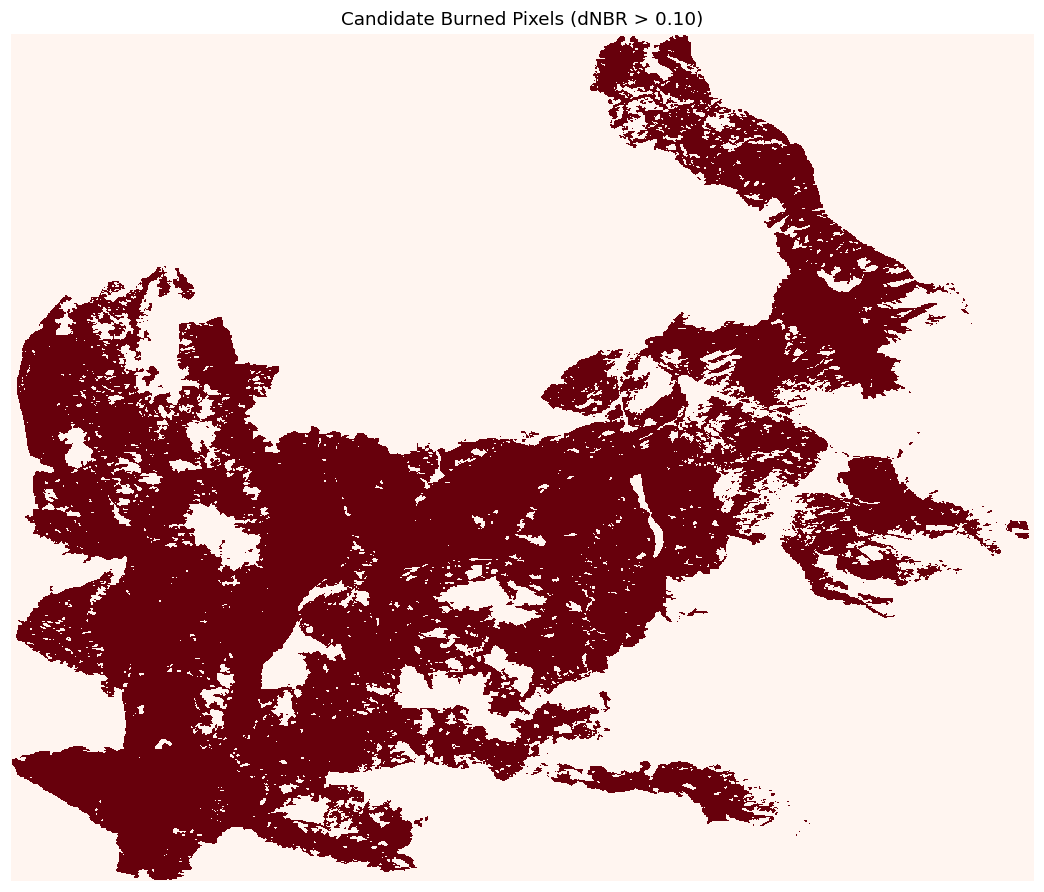

In [17]:
BURN_THRESHOLD = 0.10

# Create burned mask
burned_mask = dnbr > BURN_THRESHOLD

# Visualize burned mask
fig, ax = plt.subplots(figsize=(12, 10))
burned_mask.plot.imshow(ax=ax, cmap="Reds", add_colorbar=False)
ax.set_title("Candidate Burned Pixels (dNBR > 0.10)")
ax.axis('off')
plt.show()

The result is a candidate burned-area map. It is not yet a definitive map of the actual fire footprint: drought stress, vegetation drying, logging, harvest, and seasonal changes can also create positive dNBR.


### Classify the magnitude of dNBR change

The following classes are intended for exploratory analysis. They are broadly based on commonly used dNBR breakpoints, but they should not be interpreted as calibrated ecological severity classes for the Bug Fire without validation.

| dNBR          | Exploratory class           |
| ------------- | --------------------------- |
| Below −0.10   | Greening or negative change |
| −0.10 to 0.10 | Little apparent change      |
| 0.10 to 0.27  | Low positive change         |
| 0.27 to 0.44  | Moderate-low change         |
| 0.44 to 0.66  | Moderate-high change        |
| Above 0.66    | High positive change        |


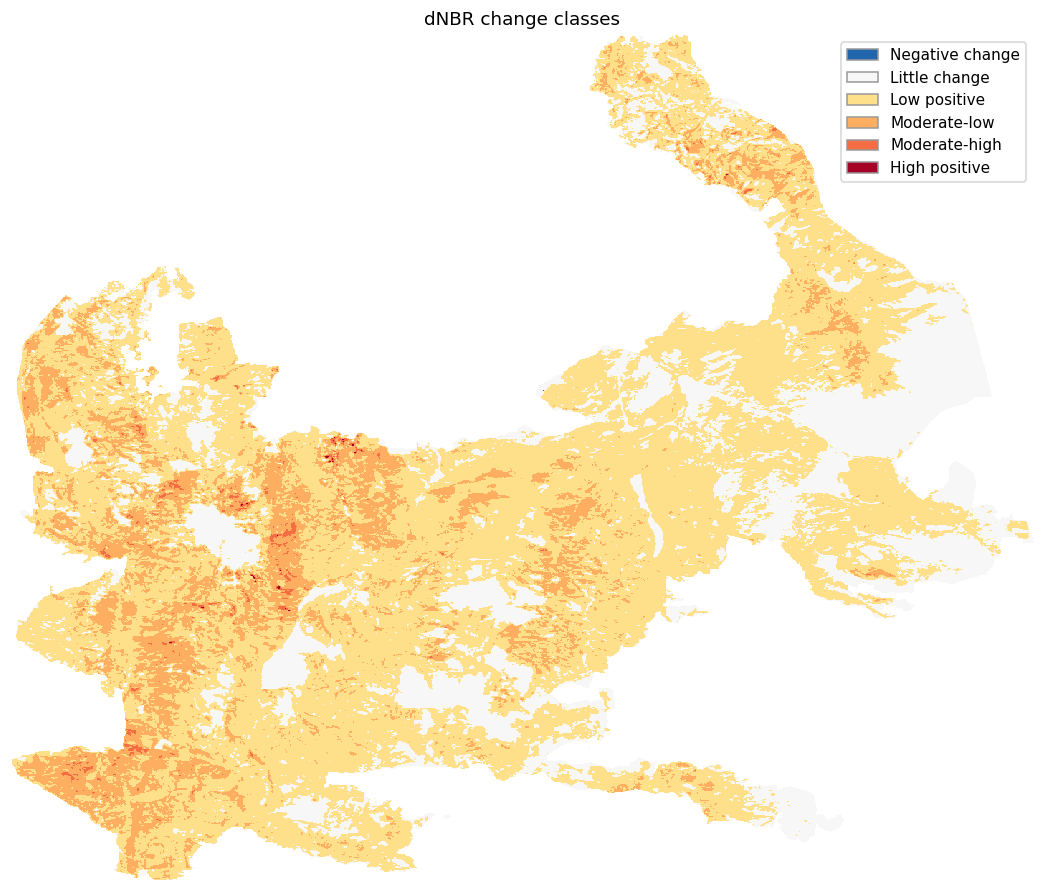

In [18]:
severity = xr.full_like(dnbr, 2, dtype="float32")
severity = xr.where(dnbr < -0.10, 1, severity)
severity = xr.where((dnbr >= -0.10) & (dnbr <= 0.10), 2, severity)
severity = xr.where((dnbr > 0.10) & (dnbr <= 0.27), 3, severity)
severity = xr.where((dnbr > 0.27) & (dnbr <= 0.44), 4, severity)
severity = xr.where((dnbr > 0.44) & (dnbr <= 0.66), 5, severity)
severity = xr.where(dnbr > 0.66, 6, severity)
severity = severity.where(dnbr.notnull())

severity_palette = {
    1: "#2166ac",
    2: "#f7f7f7",
    3: "#fee08b",
    4: "#fdae61",
    5: "#f46d43",
    6: "#a50026",
}
severity_cmap = ListedColormap([severity_palette[i] for i in range(1, 7)])
severity_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], severity_cmap.N)

fig, ax = plt.subplots(figsize=(12, 10))
severity.plot.imshow(ax=ax, cmap=severity_cmap, norm=severity_norm, add_colorbar=False)
ax.set_title("dNBR change classes")
ax.axis("off")
ax.legend(
    handles=[
        Patch(facecolor=severity_palette[1], edgecolor="0.6", label="Negative change"),
        Patch(facecolor=severity_palette[2], edgecolor="0.6", label="Little change"),
        Patch(facecolor=severity_palette[3], edgecolor="0.6", label="Low positive"),
        Patch(facecolor=severity_palette[4], edgecolor="0.6", label="Moderate-low"),
        Patch(facecolor=severity_palette[5], edgecolor="0.6", label="Moderate-high"),
        Patch(facecolor=severity_palette[6], edgecolor="0.6", label="High positive"),
    ],
    loc="upper right",
)
plt.show()


Scientific caution: dNBR measures spectral change, not fire temperature or direct ecological damage. A high dNBR value does not always correspond to high tree mortality, and low dNBR can occur in areas where fire burned through sparse vegetation. For formal burn severity assessment, compare the map with field observations or an authoritative reference product, and consider relativized dNBR (RdNBR) where appropriate.


## Estimate burned area in hectares and acres

Sentinel-2 SWIR bands are natively 20 m, so a sensible initial resolution for this analysis is 20 m. Each full 20 m × 20 m pixel represents 400 square meters, or 0.04 hectares.

We'll calculate the area of burned pixels within the fire perimeter using the pixel area from the dataset's coordinate reference system.


### Calculate the candidate burned area


In [19]:
if dnbr.rio.crs is None or not dnbr.rio.crs.is_projected:
    raise ValueError("dNBR is not on a projected CRS, so pixel area would not be in metres.")

dx = float(abs(dnbr.x[1] - dnbr.x[0]))
dy = float(abs(dnbr.y[1] - dnbr.y[0]))
pixel_area_m2 = dx * dy
print(f"Pixel resolution: {dx:.2f} m x {dy:.2f} m")
print(f"Pixel area: {pixel_area_m2:.2f} m²")

burned_pixels = int(burned_mask.sum().item())
area_m2 = burned_pixels * pixel_area_m2
print("\nCandidate burned area")
print(f"Burned pixels: {burned_pixels:,}")
print(f"Area: {area_m2:,.0f} m²")
print(f"Area: {area_m2 / 10_000:,.1f} hectares")
print(f"Area: {area_m2 / 4046.8564224:,.1f} acres")
print(f"Area: {area_m2 / 1_000_000:,.2f} km²")


Pixel resolution: 20.00 m x 20.00 m
Pixel area: 400.00 m²

Candidate burned area
Burned pixels: 721,385
Area: 288,554,000 m²
Area: 28,855.4 hectares
Area: 71,303.2 acres
Area: 288.55 km²


The number produced by this calculation is the area of pixels meeting the selected dNBR threshold inside the supplied polygon. It is not automatically the final fire acreage.

For a fair comparison with CAL FIRE's reported acreage, make sure the perimeter and imagery dates refer to the same stage of the incident, and distinguish the official incident boundary from the satellite-detected burned footprint.


### Calculate area by change class


In [20]:
# Calculate area by severity class
class_names = {
    1: "Negative change",
    2: "Little change",
    3: "Low positive change",
    4: "Moderate-low positive change",
    5: "Moderate-high positive change",
    6: "High positive change"
}

records = []
for class_id, class_name in class_names.items():
    # Count pixels in this class
    class_pixels = (severity == class_id).sum().values
    if class_pixels > 0:
        area_m2 = class_pixels * pixel_area_m2
        records.append({
            "class_id": class_id,
            "class_name": class_name,
            "area_ha": area_m2 / 10_000,
            "area_acres": area_m2 / 4046.8564224
        })

area_by_class = pd.DataFrame(records)
area_by_class

,class_id,class_name,area_ha,area_acres
0,1,Negative change,0.16,0.395369
1,2,Little change,9098.88,22483.822133
2,3,Low positive change,23075.44,57020.654037
3,4,Moderate-low positive change,5598.24,13833.552307
4,5,Moderate-high positive change,175.68,434.114734
5,6,High positive change,6.04,14.925165


This table describes the distribution of spectral change within the valid analysis area. Do not report all positive-change classes as confirmed burned land without validating the classification.


## Export the results as GeoTIFF files

`rs.write` saves a Cloud Optimized GeoTIFF under `outputs/bug_fire`. The bands, in order, are pre-fire NBR, post-fire NBR, dNBR, dNBR × 1000, pre-fire NDVI, post-fire NDVI, NDVI decrease, and NBR2 decrease. QGIS and ArcGIS Pro can open that file directly.


In [21]:
EXPORT_BANDS = [
    "NBR_pre", "NBR_post", "dNBR", "dNBR_scaled",
    "NDVI_pre", "NDVI_post", "NDVI_decrease", "NBR2_decrease",
]
export_ds = xr.Dataset(
    {
        "NBR_pre": nbr_pre,
        "NBR_post": nbr_post,
        "dNBR": dnbr,
        "dNBR_scaled": dnbr * 1000,
        "NDVI_pre": ndvi_pre,
        "NDVI_post": ndvi_post,
        "NDVI_decrease": delta_ndvi,
        "NBR2_decrease": delta_nbr2,
    }
)
export_ds = export_ds.rio.write_crs(pre_composite.rio.crs).astype("float32")

out_tif = OUT_DIR / "bug_fire_burn_indices_2026.tif"
rs.write(export_ds[EXPORT_BANDS], out_tif)
print("Wrote", out_tif.resolve())


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/outputs/bug_fire/bug_fire_burn_indices_2026.tif


The file is written locally as soon as the cell finishes. To export the candidate burned-area mask or the severity classes, pass that DataArray to `rs.write` the same way. Give it a CRS first with `.rio.write_crs(pre_composite.rio.crs)`.


## Read the GeoTIFF back and plot dNBR

This reopens the file written in Section 12, so the plot is the product on disk rather than only the in-memory array.


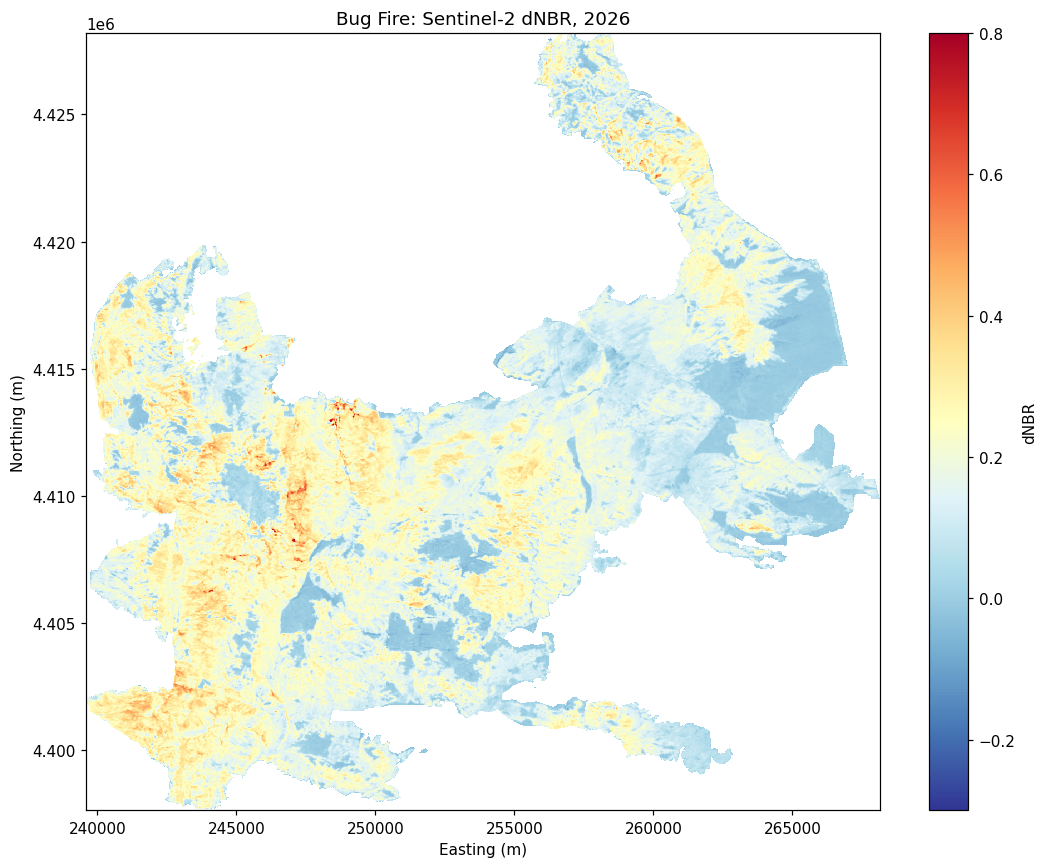

In [22]:
saved = rs.read(out_tif, band_names=EXPORT_BANDS, masked=True)

# A single-label .sel drops that dimension, so there is nothing left to squeeze.
dnbr_on_disk = saved.sel(band="dNBR")

fig, ax = plt.subplots(figsize=(10, 8))
im = dnbr_on_disk.plot.imshow(
    ax=ax,
    cmap="RdYlBu_r",
    vmin=-0.3,
    vmax=0.8,
    add_colorbar=False,
)
ax.set_title("Bug Fire: Sentinel-2 dNBR, 2026")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
fig.colorbar(im, ax=ax, label="dNBR")
plt.tight_layout()
plt.show()


Band 3 of the file is dNBR, named `dNBR` in `EXPORT_BANDS`. The axes are metres because the cube was built in the scene's UTM projection.


## Validate the burned-area map

Validation is essential before publishing a map or reporting an acreage estimate.


### Compare against independent reference data

Potential reference sources include:

- CAL FIRE incident perimeters and incident-specific mapping products.
- The [California Fire Perimeters dataset](https://data.ca.gov/@cal-fire/california-fire-perimeters-all?utm_source=chatgpt.com), where the relevant incident is available.
- Landsat or higher-resolution aerial imagery.
- Field observations or independently interpreted burned/unburned sample points.

The statewide historical perimeter dataset may not yet contain a current-year incident, and even an official fire perimeter does not necessarily mean that every enclosed pixel burned.&#x20;


### Assess classification accuracy

If you have independent reference points, create a confusion matrix with the following classes:

- Burned
- Unburned

Calculate:

$$ \text{Overall Accuracy}= \frac{\text{Correct Predictions}} {\text{Total Reference Samples}} $$

$$ \text{Precision}=\frac{TP}{TP+FP} $$

$$ \text{Recall}=\frac{TP}{TP+FN} $$

Here, $TP$ means correctly identified burned samples, $FP$ means unburned samples incorrectly classified as burned, and $FN$ means burned samples missed by the map.

In Python:


In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Independent points, not labels taken from this dNBR map.
# Required attribute: burned (0 = unburned, 1 = burned).
ref_path = Path("bug_fire_reference_points.geojson")
if not ref_path.exists():
    print(
        "Save independent reference points as bug_fire_reference_points.geojson "
        "with a 'burned' attribute (0 or 1), then re-run this cell."
    )
else:
    points = gpd.read_file(ref_path).to_crs(dnbr.rio.crs)
    sampled = dnbr.sel(
        x=xr.DataArray(points.geometry.x.to_numpy(), dims="points"),
        y=xr.DataArray(points.geometry.y.to_numpy(), dims="points"),
        method="nearest",
    )
    y_true = points["burned"].astype(int).to_numpy()
    y_pred = (sampled.values > BURN_THRESHOLD).astype(int)
    print("Overall accuracy:", accuracy_score(y_true, y_pred))
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Unburned", "Burned"],
            zero_division=0,
        )
    )


Save independent reference points as bug_fire_reference_points.geojson with a 'burned' attribute (0 or 1), then re-run this cell.


This code requires a representative set of independently labeled points. Do not evaluate the map using the same threshold-derived labels that created it; that would not provide an independent accuracy assessment.


## Common problems and solutions

| Problem                                | Possible cause                                           | Recommended solution                                        |
| -------------------------------------- | -------------------------------------------------------- | ----------------------------------------------------------- |
| No Sentinel-2 images                   | Incorrect AOI or date range                              | Verify the perimeter and expand the date window             |
| Cloudy post-fire composite             | Persistent clouds or smoke                               | Inspect individual scenes and choose clearer dates          |
| Burned area seems too large            | Threshold too permissive or drought effects              | Validate with independent imagery and reference data        |
| Burned area seems too small            | Conservative threshold or missed low-intensity fire      | Test alternative thresholds and inspect spectral composites |
| Large negative dNBR values             | Seasonal greening, moisture changes, or misaligned dates | Compare seasonal conditions and imagery quality             |
| dNBR map has holes                     | Clouds, shadows, or masked pixels                        | Inspect valid-pixel coverage and choose alternative scenes  |
| Computed acreage differs from CAL FIRE | Different perimeter dates, resolution, or definitions    | Compare equivalent spatial boundaries and dates             |


## Recommended research extensions

Once the basic workflow works, you can expand it into a more comprehensive wildfire remote-sensing project.

[Comparing Sentinel-2 and Landsat 8 for Burn Severity Mapping in Western North America | MDPI](https://images.openai.com/static-rsc-4/-fyJ6wNkrIsEkY-KhiuR7v99Pz2ddPra_92Zlh5w4Rv77ggE1fDKttWWPf1E6AqpyRgmaoTigrYwCNDY8xqIPl7uKtcdou3cXalhsB6c8dxSvyWtl2xpnA1hX39vpIrhRF5vwpZzGE_gCdCv_kKdiE3BcXWEk2ryolyAHFCpqq8?purpose=inline)

A. Multi-date burned-area monitoring

Repeat the analysis over several dates to track fire progression, changing burn extent, and vegetation recovery.

[Bagley Fire Burn Scar - NASA Science](https://images.openai.com/static-rsc-4/nTdi3lyZ3sBM0s4aHHAcjxq1OygjCPMQXQP0FWgrIxi7F2rk-yIUo2HcEdVCpVn-HApIIxGqGiinIIu96Ew_js5SO77Hkm4xYE97GT-SUuYbHKeR1bBCJzoMinHEK6kZ9i6wbWLkduQHX8OuHgSCOdi4bU13QvsnOXp7mRatdMM?purpose=inline)

B. Post-fire vegetation recovery

Track NDVI, NBR, and NDMI for months or years after the incident to characterize recovery trajectories.

[Wildfire Burn Map in 2021 California | Spatialnode](https://images.openai.com/static-rsc-4/z4ReSq1UFZqSkm_z996jssHTxggTrd2-8I5c1RZthg1suzIqUU3ZTK_kZdGwABDiogWDCNPmhY2nsxCk9VTf0_2CZOtmR2ZtpWCF1VQNntfNAy-AIAVGUMVgXPvC--OxYd7FB0ahrqqXFpZMzwgxFq3nYcdnG2FtSxpNJvQiZus?purpose=inline)

C. Terrain and environmental factors

Combine burn severity with slope, elevation, aspect, land cover, and pre-fire vegetation conditions to explore spatial patterns in fire impact.

[Mapping of Post-Wildfire Burned Area Using a Hybrid Algorithm and Satellite Data: The Case of the Camp Fire Wildfire in California, USA | MDPI](https://images.openai.com/static-rsc-4/5Vf1x36cyxl0Pmj2dpJCuHu9biqn6Ps5Dat2rRtBRig3EGE6fq_z_LS8X37zOowSyBUdqiJvqxJPPE0foSJzicqaQrs74ftiDcXSchiFWEwLyoatEiuGpfTnixfM097aeTfZpBd7jjxHFnHyl7hdGAsNyO7KSe1Vz9DxsL-kaLc?purpose=inline)

D. Machine-learning classification

Use Random Forest or XGBoost with spectral bands, burn indices, terrain, and reference labels to classify burned versus unburned pixels.


## Final workflow summary

CAL FIRE incident and perimeter

Sentinel-2 Level-2A GeoTIFFs downloaded with `get_images`

Local pre-fire and post-fire cubes, scaled and cloud-masked

Median composites

NBR · dNBR · NDVI · NBR2 · BAIS2

Candidate burned pixels and change classes

Area statistics, a local GeoTIFF, and validation against independent points

Start with the Bug Fire, confirm that the perimeter is the fire and not the county, inspect the downloaded scenes, and then calculate NBR and dNBR. Treat the first threshold map as a preliminary product until it has been checked against independent reference data.
